# Scotland: a "what-if" scenario, not a forecast

**Project:** Why Britain voted Leave, and where the explanation breaks (optional extension of the Scotland section)

**The question:** *if Scotland as a whole voted X% Yes in another independence referendum, which councils would vote Yes, assuming the 2014 geography still holds?*

**What this is NOT:** a prediction of whether Yes would win. Our data can't tell us the national level. That depends on polls, campaigns and events. Our scope rule stands: *no forecast of a future independence referendum*. We choose the national level ourselves (45%, 48%, 50%, 52%, 55%) and only ask how it would be **spread across councils**.

**Where this notebook fits in the project**

| Notebook | What it does |
|---|---|
| 01 Data exploration | Finds the patterns with charts and maps |
| 02 Statistical tests | Tests whether the patterns are real and how big they are |
| 03 Scotland in depth | Compares Scotland's 2016 EU vote with its 2014 independence vote |
| **04 What-if scenario (this one, optional)** | Shows how a future independence vote could spread across councils, without predicting it |
| Tableau dashboards | Present the results; this notebook exports a scenario file for them (section 6) |

**Context (November 2026):** the Scottish Parliament backed a motion in May 2026 asking for a new referendum. The UK government rejected it, and the Supreme Court has ruled that Holyrood can't hold one without Westminster's approval. No referendum is scheduled.

## Key terms in simple words

| Term | Meaning |
|---|---|
| **Council** | One of Scotland's 32 local authorities. The 2014 referendum was counted by council, so councils are our units. |
| **Yes share** | Yes votes as a share of valid votes (Yes + No) in a council. |
| **National share** | The Yes share for the whole of Scotland: all Yes votes divided by all valid votes. 44.7% in 2014. |
| **Swing** | The change in a vote share between two votes, in percentage points. From 44.7% to 50% is a swing of +5.3 points. |
| **Uniform swing** | The assumption that every council moves by the **same** number of points. |
| **Proportional (logit) swing** | An alternative where councils near 50% move a bit more and councils far from 50% move a bit less. |
| **Tipping point** | The national Yes level at which a council would switch from No to Yes. |
| **Weight** | How much a council counts in the national total: its share of all valid votes. Glasgow counts much more than Orkney. |
| **Scenario** | A "what if" calculation where **we choose** the starting assumption. It's not a forecast. |
| **Forecast** | A prediction of what **will** happen. This notebook doesn't make one. |

## How the method works: uniform swing

**Swing** is the change in a vote share between two elections. **Uniform swing** assumes every council moves by **the same number of points**.

Example: Yes got 44.7% in Scotland in 2014. If the national Yes vote rose to 50%, that's a swing of **+5.3 points**. Uniform swing adds 5.3 points to every council:
- Glasgow: 53.5% → 58.8%
- Edinburgh: 38.9% → 44.2%

**What it assumes**

1. Councils keep the **same order** as in 2014 (the most Yes stays the most Yes).
2. Every council moves by the **same amount**.
3. Each council's **share of the national vote** stays as in 2014 (same turnout pattern).

**An everyday example:** imagine a class where every student's mark goes up by 5 points after an easier exam. A student on 47 moves to 52 and now passes; a student on 30 moves to 35 and still fails. Uniform swing does the same with councils: each one moves by the same amount, and we look at which ones cross the 50% line.

We test assumptions 2 and 3 in sections 4 and 5. Assumption 1 is the big one: we can't check it with our data (see section 7).

**Why it's useful anyway:** election analysts use uniform swing as a simple, transparent baseline. It answers one clear question well: **where are the tipping points?**

## 1. Setup and data

We only need the Scotland table and the boundaries. The map helpers are the same as in notebook 03.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.collections import PolyCollection
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy.optimize import brentq

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
SCOTLAND, LONDON, OTHER, PURPLE = "#2a78d6", "#eb6834", "#b5b3ac", "#4a3f9f"
vote_colours = LinearSegmentedColormap.from_list("vote", [SCOTLAND, "#ece9e2", LONDON])
vote_scale = TwoSlopeNorm(vmin=30, vcenter=50, vmax=70)

DATA_DIR = Path("../data")  # the data folder of this repository
sc = pd.read_csv(DATA_DIR / "scotland_2014_2016.csv")
with open(DATA_DIR / "gb_areas_boundaries.geojson") as f:
    features = [f for f in json.load(f)["features"] if f["properties"]["code"].startswith("S")]

# Map helpers (same as notebook 03)
SHAPES, SHAPE_CODES = [], []
for f in features:
    g = f["geometry"]
    for p in (g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]]):
        SHAPES.append(np.asarray(p[0]))
        SHAPE_CODES.append(f["properties"]["code"])


def draw_scotland(ax, values):
    layer = PolyCollection(SHAPES, array=np.array([values[c] for c in SHAPE_CODES]), cmap=vote_colours,
                           norm=vote_scale, edgecolors="white", linewidths=0.3)
    ax.add_collection(layer)
    ax.set_xlim(-7.7, -0.7)
    ax.set_ylim(54.6, 60.9)
    ax.set_aspect(1.75)
    ax.set_axis_off()
    return layer


print(len(sc), "councils,", len(features), "shapes")

32 councils, 32 shapes


## 2. Step 1: the baseline and each council's tipping point

**What this cell does**

1. It computes the **2014 national Yes share** from votes: 44.7%.
2. For each council, it computes the **swing needed to reach 50%**: 50 minus its 2014 Yes share. Dundee is already above 50%, so its number is negative.
3. Under uniform swing, the national share rises by the same amount as each council. So each council's **tipping point** is: *2014 national share + swing needed*. It's the national Yes level at which that council would switch to Yes.

**How to read the chart:** each bar is a council's tipping point. The dashed line is 50% nationally. Councils with bars to the left of the line would vote Yes if Scotland as a whole voted 50%.

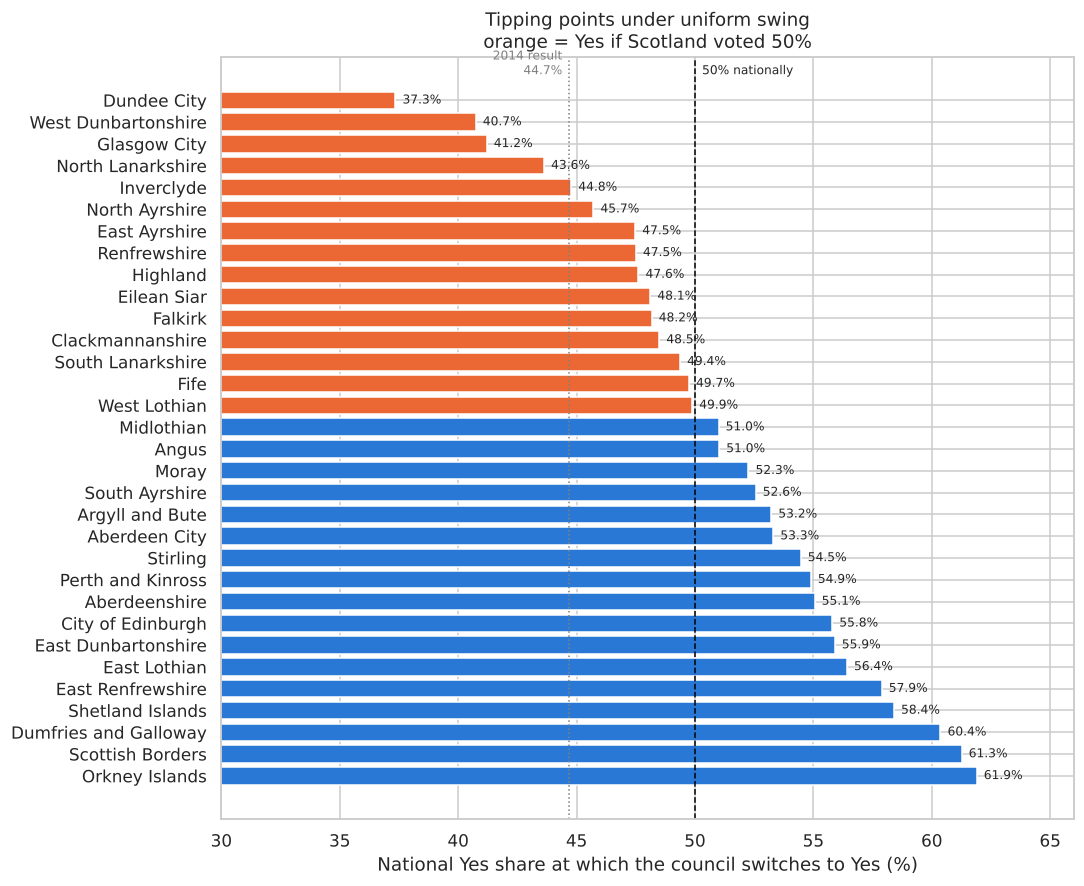

National Yes share, 2014: 44.7%


,area,yes_pct,swing_needed,tipping_point
0,Dundee City,57.3,-7.3,37.3
1,West Dunbartonshire,54.0,-4.0,40.7
2,Glasgow City,53.5,-3.5,41.2
3,North Lanarkshire,51.1,-1.1,43.6
4,Inverclyde,49.9,0.1,44.8
5,North Ayrshire,49.0,1.0,45.7
6,East Ayrshire,47.2,2.8,47.5
7,Renfrewshire,47.2,2.8,47.5
8,Highland,47.1,2.9,47.6
9,Eilean Siar,46.6,3.4,48.1


In [2]:
sc["valid_2014"] = sc["yes_votes"] + sc["no_votes"]
weights = sc["valid_2014"] / sc["valid_2014"].sum()          # each council's share of the national vote
national_2014 = (sc["yes_pct"] * weights).sum()
print(f"National Yes share, 2014: {national_2014:.1f}%")

sc["swing_needed"] = 50 - sc["yes_pct"]
sc["tipping_point"] = national_2014 + sc["swing_needed"]
tips = sc.sort_values("tipping_point").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 9))
colours = [LONDON if t <= 50 else SCOTLAND for t in tips["tipping_point"]]
ax.barh(tips["area"], tips["tipping_point"], color=colours)
ax.axvline(50, color="black", linestyle="--", linewidth=1)
ax.axvline(national_2014, color="grey", linestyle=":", linewidth=1)
ax.text(national_2014 - 0.3, -1.2, "2014 result\n44.7%", ha="right", fontsize=8, color="grey")
ax.text(50.3, -1.2, "50% nationally", fontsize=8)
for i, t in enumerate(tips["tipping_point"]):
    ax.text(t + 0.3, i, f"{t:.1f}%", va="center", fontsize=8)
ax.invert_yaxis()
ax.set_xlim(30, 66)
ax.set_xlabel("National Yes share at which the council switches to Yes (%)")
ax.set_title("Tipping points under uniform swing\norange = Yes if Scotland voted 50%")
plt.show()

display(tips[["area", "yes_pct", "swing_needed", "tipping_point"]].round(1))

**What we see**

- **Already Yes in 2014:** Dundee, West Dunbartonshire, Glasgow and North Lanarkshire.
- **Close behind:** Inverclyde would flip at 44.8% nationally, almost the 2014 result (it missed by 86 votes). North Ayrshire would flip at 45.7%.
- **The 47.5-50% band** holds many councils: East Ayrshire, Renfrewshire, Highland, Eilean Siar, Falkirk, Clackmannanshire, South Lanarkshire, Fife and West Lothian. A close national vote would be decided in the **west-central belt, Fife and the Highlands**.
- **Hardest for Yes:** Orkney (61.9%), the Scottish Borders (61.3%), Dumfries and Galloway (60.4%) and Shetland (58.4%). Even a clear national Yes win wouldn't flip them.
- **Edinburgh** (55.8%) and the wealthy suburbs (East Dunbartonshire 55.9%, East Renfrewshire 57.9%) would stay No unless Yes won by a wide margin.

## 3. Step 2: maps of five scenarios

**What this cell does:** it picks five national Yes levels, adds the same swing to every council, and maps the result. The first map (44.7%) is the real 2014 result.

`np.clip` keeps every share between 0 and 100, which only matters for extreme swings.

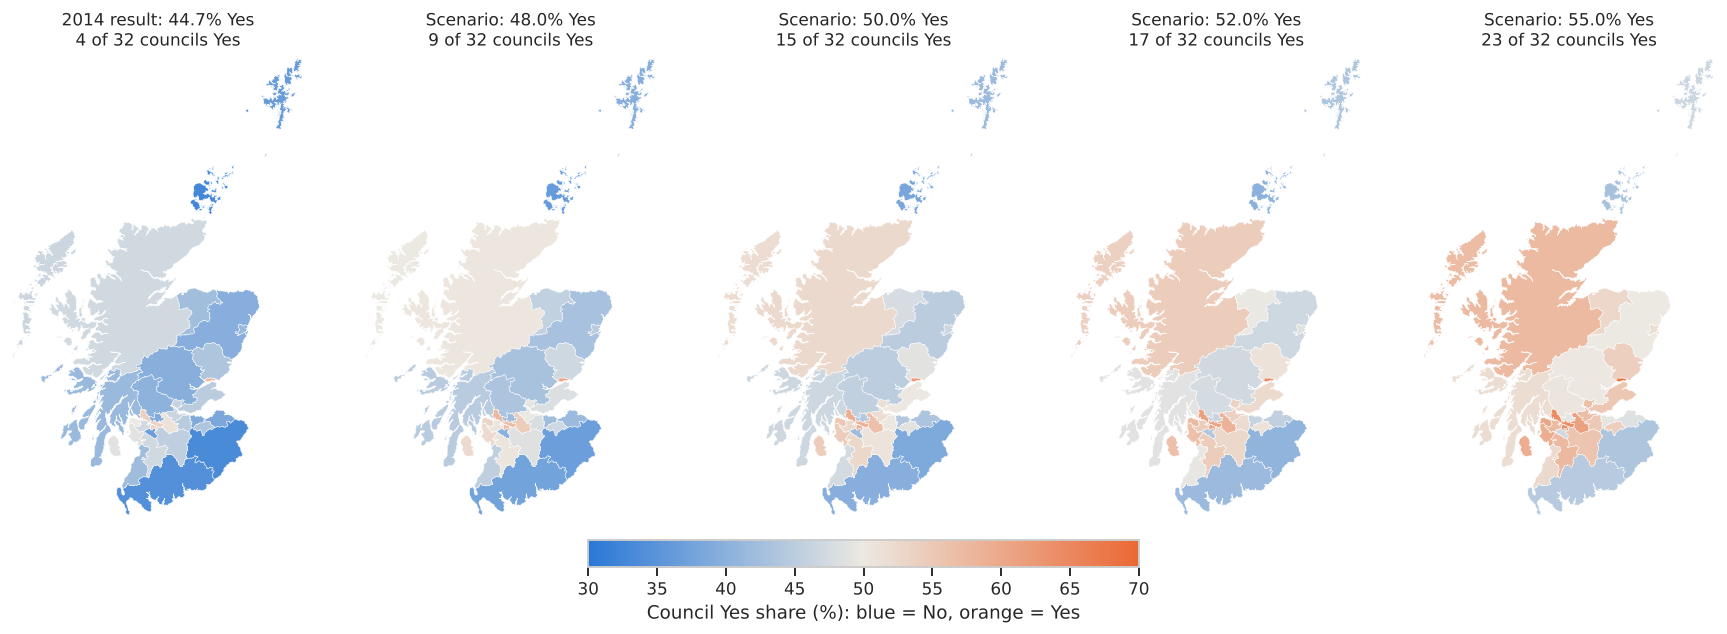

,national_yes,councils_yes,share_of_voters_in_yes_councils_%
0,44.7,4,20.6
1,48.0,9,34.9
2,50.0,15,55.9
3,52.0,17,59.8
4,55.0,23,74.1


In [3]:
SCENARIOS = [national_2014, 48, 50, 52, 55]

fig, axes = plt.subplots(1, 5, figsize=(20, 6.5))
rows = []
for ax, target in zip(axes, SCENARIOS):
    shares = np.clip(sc["yes_pct"] + (target - national_2014), 0, 100)
    yes_councils = int((shares > 50).sum())
    yes_electorate = sc.loc[shares > 50, "valid_2014"].sum() / sc["valid_2014"].sum()
    layer = draw_scotland(ax, pd.Series(shares.to_numpy(), index=sc["code"]))
    label = "2014 result" if target == national_2014 else "Scenario"
    ax.set_title(f"{label}: {target:.1f}% Yes\n{yes_councils} of 32 councils Yes", fontsize=11)
    rows.append({"national_yes": round(target, 1), "councils_yes": yes_councils,
                 "share_of_voters_in_yes_councils_%": round(100 * yes_electorate, 1)})
fig.colorbar(layer, ax=axes, orientation="horizontal", fraction=0.05, pad=0.04,
             label="Council Yes share (%): blue = No, orange = Yes")
plt.show()
display(pd.DataFrame(rows))

**What we see**

| National Yes | Councils voting Yes |
|---|---|
| 44.7% (2014) | 4 |
| 48% | 9 |
| **50%** | **15 of 32** |
| 52% | 17 |
| 55% | 23 |

**The key insight:** at exactly 50% nationally, Yes would win **fewer than half the councils (15)**, but those councils hold **more than half the voters**. Yes support is concentrated in large urban councils (Glasgow, Lanarkshire, Fife), while No wins many small rural and island councils. So **"councils won" is a misleading measure** of a national referendum. Only total votes count. The same point applies to the Brexit maps: big rural areas fill the map but hold fewer voters.

## 4. Step 3: robustness check, proportional swing

**The problem with uniform swing:** adding the same 5 points to a council at 33% and one at 57% isn't equally realistic. Shares near 0% or 100% can't move as freely as shares near 50%.

**Proportional (logit) swing** is the standard alternative. Instead of adding points to the share, it adds the same amount to the **log-odds** of the share, `log(p / (1 - p))`. In practice, councils near 50% move a bit more and councils far from 50% move a bit less.

**What this cell does:** for each scenario it finds (with `brentq`, a root-finding function) the log-odds shift that gives exactly the target national share, then compares the two methods.

In [4]:
def logit(p):
    return np.log(p / (1 - p))


def inv_logit(x):
    return 1 / (1 + np.exp(-x))


def logit_swing(target):
    # Find the shift d so that the vote-weighted national share equals the target
    base = logit(sc["yes_pct"] / 100)
    d = brentq(lambda d: (inv_logit(base + d) * weights).sum() * 100 - target, -5, 5)
    return 100 * inv_logit(base + d)


rows = []
for target in [48, 50, 52, 55]:
    uniform = sc["yes_pct"] + (target - national_2014)
    proportional = logit_swing(target)
    rows.append({"national_yes": target, "councils_yes_uniform": int((uniform > 50).sum()),
                 "councils_yes_proportional": int((proportional > 50).sum()),
                 "largest_difference_points": round(float((uniform - proportional).abs().max()), 2)})
display(pd.DataFrame(rows))

,national_yes,councils_yes_uniform,councils_yes_proportional,largest_difference_points
0,48,9,9,0.27
1,50,15,15,0.38
2,52,17,17,0.46
3,55,23,23,0.50


**How to read the table:** each row is one national Yes level. The two middle columns count the Yes councils under each method. The last column is the biggest difference, in points, between the two methods for any single council.

**What we see:** both methods give **the same number of Yes councils** in every scenario, and council shares differ by **less than a point**. Scotland's councils are all fairly close to the middle (33-57% Yes), so the choice of method doesn't change the conclusions. That makes the results more solid.

## 5. Step 4: robustness check, a different turnout pattern

Notebook 03 showed that turnout fell most in the **Yes councils** between 2014 and 2016. If a new referendum had 2016-style turnout, Yes councils would carry **less weight** in the national total.

**What this cell does:** it keeps each council's 2014 Yes share but weights councils by an **estimated 2016-style electorate turnout** instead of 2014 turnout, and recomputes the national share.

In [5]:
electorate_2014 = sc["valid_2014"] / (sc["turnout_2014_pct"] / 100)
weights_2016_turnout = electorate_2014 * sc["turnout_pct"] / 100
weights_2016_turnout = weights_2016_turnout / weights_2016_turnout.sum()

national_low_turnout = (sc["yes_pct"] * weights_2016_turnout).sum()
print(f"2014 council shares with 2014 turnout:        {national_2014:.2f}% Yes")
print(f"2014 council shares with 2016-style turnout:  {national_low_turnout:.2f}% Yes")
print(f"Difference: {national_low_turnout - national_2014:+.2f} points")

2014 council shares with 2014 turnout:        44.70% Yes
2014 council shares with 2016-style turnout:  44.47% Yes
Difference: -0.23 points


**How to read the result:** the first line is the real 2014 result. The second line keeps every council's 2014 Yes share but changes how much each council counts, as if turnout followed the 2016 pattern. The difference shows how much the turnout pattern alone moves the national share.

**What we see:** with 2016-style turnout, the same council results give about **44.5% Yes instead of 44.7%**, a drop of only about **0.2 points**. Turnout differences between councils matter little at national level.

**But careful:** this only reweights councils. It can't capture turnout differences **within** councils (for example, if younger or poorer Yes voters stayed home inside Glasgow). Notebook 03 suggests that's where the real effect is, and our data can't measure it.

## 6. Step 5: export the scenarios for Tableau

A Tableau dashboard can show these scenarios on a map, for example with a **slider** that picks the national Yes level. This cell saves one row per council with everything the dashboard needs.

**What the file holds, column by column**

- `code`, `area`: the council's code (for joining with the map outlines) and its name.
- `yes_pct_2014`: the real 2014 Yes share.
- `valid_votes_2014`: how many valid votes the council cast, which is its weight in the national total.
- `tipping_point`: the national Yes level at which the council would switch to Yes (section 2).
- `yes_at_48`, `yes_at_50`, `yes_at_52`, `yes_at_55`: the council's Yes share under each scenario, with uniform swing.

**How to use it in Tableau:** open `gb_areas_boundaries.geojson` as a **Spatial file**, add `tableau_scotland_scenarios.csv` as a **Text file**, and join them on `code`. Only the 32 Scottish councils will match, which is what we want. Colour the map by one of the `yes_at_` columns, or build a parameter that compares each council's `tipping_point` with a chosen national level: councils whose tipping point is below that level vote Yes.

In [6]:
scenarios = sc[["code", "area", "yes_pct", "valid_2014", "tipping_point"]].rename(
    columns={"yes_pct": "yes_pct_2014", "valid_2014": "valid_votes_2014"})

# Each council's Yes share under each national level, with uniform swing
for target in [48, 50, 52, 55]:
    scenarios[f"yes_at_{target}"] = np.clip(sc["yes_pct"] + (target - national_2014), 0, 100)

scenarios = scenarios.sort_values("tipping_point").round(2)
scenarios.to_csv(DATA_DIR / "tableau_scotland_scenarios.csv", index=False)
print("Saved tableau_scotland_scenarios.csv:", scenarios.shape)
display(scenarios.head(8))

Saved tableau_scotland_scenarios.csv: (32, 9)


,code,area,yes_pct_2014,valid_votes_2014,tipping_point,yes_at_48,yes_at_50,yes_at_52,yes_at_55
7,S12000042,Dundee City,57.35,93500,37.35,60.65,62.65,64.65,67.65
30,S12000039,West Dunbartonshire,53.96,62496,40.74,57.26,59.26,61.26,64.26
15,S12000046,Glasgow City,53.49,364126,41.20,56.80,58.80,60.80,63.80
21,S12000044,North Lanarkshire,51.07,226705,43.62,54.38,56.38,58.38,61.38
17,S12000018,Inverclyde,49.92,54572,44.78,53.22,55.22,57.22,60.22
20,S12000021,North Ayrshire,48.99,96088,45.71,52.29,54.29,56.29,59.29
8,S12000008,East Ayrshire,47.22,84204,47.48,50.52,52.52,54.52,57.52
24,S12000038,Renfrewshire,47.19,117533,47.50,50.50,52.50,54.50,57.50


**What we see:** 32 rows, one per council, sorted by tipping point. Dundee, West Dunbartonshire, Glasgow and North Lanarkshire come first: they were already Yes in 2014, so their tipping point is below 44.7%.

## 7. Limits, and how to present this

**The main limit: the 2014 geography may have changed.** Uniform swing assumes councils keep their 2014 order. Since 2014, Brexit, Covid and new generations of voters may have reshaped it. Notebook 03 already showed that the 2016 Remain map was very different from the Yes map.

**How you could check it (optional, needs new data)**
- Download **Scottish Parliament 2021 or 2026 constituency results** (SNP + Green share as a rough proxy for pro-independence support).
- Map constituencies to councils (many constituencies sit inside one council; some cross borders, so use the main council).
- Correlate the proxy with Yes 2014. A high r (above about 0.8) would suggest the geography has held; a low r would mean uniform swing from 2014 isn't reliable.
- Caveat: party vote isn't the same as a referendum vote. About 1 in 5 SNP voters voted No in 2014 (RP14/50).

**Other limits**
- 32 councils, one past referendum: no way to validate the method on Scottish data.
- The electorate would differ: new voters, people who moved, and 16-17-year-olds again.
- It describes councils, not voters.

**How to word it on a slide**

> *Scenario, not forecast: if Scotland voted 50% Yes and the 2014 geography still held, Yes would win 15 of 32 councils, mainly in the west-central belt. Councils won don't decide a referendum; votes do.*

**What not to say:** "Scotland would vote X%", "Yes will win", or anything about the likely national result.

## 8. The whole notebook in simple words

1. **The idea:** we don't predict the national result. We pick a national Yes level and ask which councils would vote Yes, if every council moved by the same amount as in 2014.
2. **Tipping points:** each council has a national Yes level at which it would switch. Inverclyde would switch almost immediately (44.8%). Orkney would need 61.9%.
3. **Scenarios:** at 50% Yes nationally, 15 of 32 councils would vote Yes. They're the big urban councils, so they hold more than half the voters.
4. **Checks:** a different swing method gives the same answers, and a 2016-style turnout pattern changes the national share by only about 0.2 points.
5. **Tableau:** we save one row per council with its tipping point and its share in each scenario, ready for a map with a slider.
6. **Limit:** everything depends on the 2014 geography still holding. Checking it would need recent Scottish Parliament results.